# Toy four-zone model

A small, hand-checkable version of a four-stage transport model. Every number is made up, so each step can be checked by hand. Nothing here is Salisbury data.

The notebook is built in **five levels**. Each level keeps everything from the level before and adds one new idea. You can stop at any level and still have a working model.

| Level | What it adds | Parts |
|---|---|---|
| 1 | One purpose (home-based work), doubly constrained gravity, travel time only | A to E |
| 2 | A second purpose (home-based other), singly constrained, its own deterrence | F to G |
| 3 | Mode choice: car availability, money and walk/wait costs, calibrated constant | H to J |
| 4 | Assignment: convert person trips to vehicles, route trips on the network | K to L |
| 5 | Validation: GEH, screenlines, journey times, pass/fail summary | M to N |

**Units:** trips per hour (trips/h), minutes (min), vehicles per hour on roads (veh/h), pounds (£).

**Plan link.** The notebook follows Phases 0 to 6 of the Salisbury project plan, at toy scale. Placeholder values are marked as placeholders, to be replaced with TAG values later.

**TAG references.** Each decision in the notebook is referenced to a TAG unit and section in its Part. The same references, with a status for each, are in `docs/methodology.md`.

## Setup

Three tools: `numpy` does the matrix arithmetic, `pandas` makes tables easy to read, and `matplotlib` draws the one graph.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 100)

ZONES = ["A", "B", "C", "D"]

# Level 1: one purpose, travel time only

At this level there is one trip purpose (home-based work, HBW), one mode, and travel time as the only cost. The four steps are: build the network times, set the trip ends, add deterrence, and balance the trips.

## Part A. Network and travel times

**Question.** How long does it take to travel between each pair of zones?

**First principles.** A road network is a set of **nodes** (places) and **links** (roads between them). Each link has a travel time. The time from one zone to another is the total time along the quickest sequence of links between them.

We need three things:

1. **The links:** which zones they connect, and the **free-flow time** (how long a link takes when it is empty).
2. **The capacity** of each link, in vehicles per hour. We need this in Part K.
3. **The shortest time** between every pair of zones.

**Assumption:** links are two-way and take the same time in both directions.

**TAG reference.** Network structure: TAG M3.1 section 2.4. Two-way links are a simplification, not checked against TAG. Free-flow times and capacities are placeholders. Speed/flow functions are in TAG M3.1 Appendix E.

In [2]:
# Five two-way links between the four zones.
links = pd.DataFrame(
    [
        ("A", "B", 10, 60),
        ("B", "C", 12, 50),
        ("C", "D", 8, 100),
        ("D", "A", 15, 60),
        ("A", "C", 20, 40),
    ],
    columns=["from", "to", "free_flow_min", "capacity_vph"],
)
links

,from,to,free_flow_min,capacity_vph
0,A,B,10,60
1,B,C,12,50
2,C,D,8,100
3,D,A,15,60
4,A,C,20,40


### Shortest times between all pairs

**First principles (Floyd–Warshall).** Start with the link times: a zone is 0 minutes from itself, and zones with no direct link are infinitely far apart. Then, for each zone $k$ in turn, check every pair $(i, j)$: is going $i \to k \to j$ quicker than the best time found so far? If so, keep the quicker time.

Any route either goes directly, or passes through some zone. Trying each zone as a possible stop-over covers every route, so the final table holds the shortest times.

In [3]:
n = len(ZONES)
idx = {z: k for k, z in enumerate(ZONES)}

# Direct link times as a matrix. No direct link = infinity. A zone to itself = 0.
link_time = np.full((n, n), np.inf)
np.fill_diagonal(link_time, 0.0)
for _, row in links.iterrows():
    i, j = idx[row["from"]], idx[row["to"]]
    link_time[i, j] = link_time[j, i] = row["free_flow_min"]

# Floyd-Warshall: try each zone k as a stop-over.
best = link_time.copy()
for k in range(n):
    for i in range(n):
        for j in range(n):
            best[i, j] = min(best[i, j], best[i, k] + best[k, j])

pd.DataFrame(best, index=ZONES, columns=ZONES)

,A,B,C,D
A,0.0,10.0,20.0,15.0
B,10.0,0.0,12.0,20.0
C,20.0,12.0,0.0,8.0
D,15.0,20.0,8.0,0.0


### Trips within a zone

**First principles.** A trip from a zone to itself still takes time (you cross the zone), but less than a trip to the next zone. A common rule of thumb is half the time to the nearest other zone.

A zero would make intrazonal trips look free, so the deterrence function (Part C) would treat them as the most attractive trips in the model.

**TAG reference.** Matches TAG M2.2 section 5.2.28: a measure of intrazonal cost based on the lowest inter-zonal cost, with a cap for large zones at mean trip distance (the cap is not needed at four zones). Also M2.1 section 2.4.4 (zone size and intrazonals).

In [4]:
# Travel time matrix c (minutes). Intrazonal time = half the time to the nearest other zone.
c = best.copy()
for i in range(n):
    nearest = min(best[i, j] for j in range(n) if j != i)
    c[i, i] = nearest / 2

assert np.allclose(c, c.T), "the matrix should be symmetric"

pd.DataFrame(c, index=ZONES, columns=ZONES)

,A,B,C,D
A,5.0,10.0,20.0,15.0
B,10.0,5.0,12.0,20.0
C,20.0,12.0,4.0,8.0
D,15.0,20.0,8.0,4.0


## Part B. Productions and attractions (HBW)

**Question.** How many work trips start and end in each zone?

**First principles.** Every trip has one start and one end. The total leaving every zone must equal the total arriving at every zone:

$$\sum_i P_i = \sum_j A_j$$

- **Productions** $P_i$: trips starting in zone $i$. For work trips these come from the workers who live there.
- **Attractions** $A_j$: trips ending in zone $j$. For work trips these come from the jobs there.

First guesses for attractions rarely add up to the productions total, so we scale them:

$$A_j = A_j^{\text{raw}} \cdot \frac{\sum_i P_i}{\sum_k A_k^{\text{raw}}}$$

We keep the productions and scale the attractions, because productions come from household data and are usually more reliable.

**TAG reference.** Not checked. Trip generation is outside this toy model. The productions and attractions are placeholders, to be sourced in the real model.

In [5]:
P_w = np.array([400.0, 300.0, 200.0, 100.0])      # HBW productions, trips/h
A_raw = np.array([550.0, 150.0, 150.0, 250.0])    # first-guess HBW attractions, trips/h

A_w = A_raw * (P_w.sum() / A_raw.sum())

print("sum of P_w    =", P_w.sum())
print("sum of A_raw  =", A_raw.sum())
print("sum of A_w    =", A_w.sum())
print("A_w           =", A_w)
assert np.isclose(P_w.sum(), A_w.sum())

sum of P_w    = 1000.0
sum of A_raw  = 1100.0
sum of A_w    = 1000.0
A_w           = [500.     136.3636 136.3636 227.2727]


## Part C. Deterrence: how travel time puts people off

**Question.** How much weight should a pair of zones get, given the travel time between them?

**First principles.** Two ideas:

- People prefer shorter trips, so the weight should fall as travel time rises.
- Each extra minute should put off the same *share* of trips, not the same number. Going from 10 to 20 minutes should cut trips by the same percentage as going from 40 to 50.

A function with that property is the exponential:

$$f(c) = e^{-\beta c}$$

- Each extra minute multiplies the weight by $e^{-\beta}$, a fixed fraction.
- $f(0) = 1$: no travel time, no deterrence.
- $f$ is never negative, so a trip count cannot go below zero.
- $\beta$ (per minute) sets how fast the weight falls. A bigger $\beta$ means people give up on long trips sooner.

We use $\beta_w = 0.05$ for work. A 9-minute trip keeps about 64% of its weight, and a 60-minute trip keeps about 5%. There is no survey data here to calibrate against, so this is a placeholder. Plan Phase 3 calibrates $\beta$ against the observed trip length distribution.

**TAG reference.** Exponential deterrence form: M2.1 section 4.9.14 (logit or exponential form). $eta$ is a placeholder. TAG M2.2 section 5.2.31 says to calibrate the deterrence function against observed trip-length data.

In [6]:
beta_w = 0.05   # per minute, HBW (placeholder)

def deterrence(t, beta):
    return np.exp(-beta * t)

F_w = deterrence(c, beta_w)   # F_w[i, j] = f(c_ij)
pd.DataFrame(F_w, index=ZONES, columns=ZONES).round(3)

,A,B,C,D
A,0.779,0.607,0.368,0.472
B,0.607,0.779,0.549,0.368
C,0.368,0.549,0.819,0.670
D,0.472,0.368,0.670,0.819


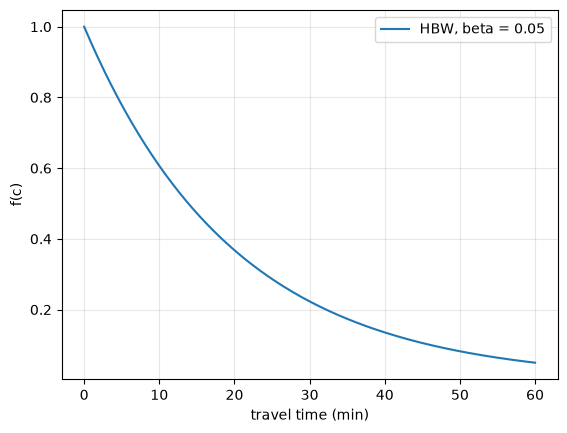

In [7]:
t = np.linspace(0, 60, 200)
plt.plot(t, deterrence(t, beta_w), label=f"HBW, beta = {beta_w}")
plt.xlabel("travel time (min)")
plt.ylabel("f(c)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Part D. The first guess: unconstrained gravity

**Question.** If trips only depended on size and distance, how many would there be?

**First principles.** A zone is more likely to send and receive trips if it is big. A pair of zones is more likely to trade trips if it is close. Multiply the three things together:

$$T^0_{ij} = P_i \, A_j \, f(c_{ij})$$

This is Newton's idea of gravity: two bodies attract in proportion to their masses and fall off with distance.

**Problem.** Nothing forces the row totals to equal $P_i$ or the column totals to equal $A_j$. Part E fixes that.

The numbers below look far too big, and that is expected. Multiplying a production (hundreds) by an attraction (hundreds) gives tens of thousands before the deterrence factor is applied. The balancing factors in Part E shrink them back to the right totals.

**TAG reference.** Gravity form: M2.1 section 4.9.14. The unbalanced totals are a first guess, so no TAG parameter applies at this step.

In [8]:
T0 = P_w[:, None] * A_w[None, :] * F_w   # T0[i, j] = P_i * A_j * f(c_ij)

print("row sums:    ", T0.sum(axis=1).round(1), "  target P:", P_w)
print("column sums: ", T0.sum(axis=0).round(1), "  target A:", A_w.round(1))

row sums:     [251852.2 170373.7 104553.6  56383.1]   target P: [400. 300. 200. 100.]
column sums:  [307146.   84927.7  73987.3 117101.7]   target A: [500.  136.4 136.4 227.3]


## Part E. Balancing the trips (Furness method)

**Question.** How do we adjust the first guess so that every zone sends out exactly $P_i$ trips and receives exactly $A_j$ trips?

**First principles.** Multiply each row by a number $a_i$ and each column by a number $b_j$:

$$T_{ij} = a_i \, b_j \, P_i \, A_j \, f(c_{ij})$$

We need two constraints:

- Row: $\sum_j T_{ij} = P_i$
- Column: $\sum_i T_{ij} = A_j$

Take the row constraint and solve for $a_i$, holding the $b$s fixed:

$$\sum_j a_i \, b_j \, P_i \, A_j \, f(c_{ij}) = P_i \quad\Rightarrow\quad a_i = \frac{1}{\sum_j b_j \, A_j \, f(c_{ij})}$$

The column constraint gives the same kind of rule for $b_j$:

$$b_j = \frac{1}{\sum_i a_i \, P_i \, f(c_{ij})}$$

Each rule needs the other set of factors, so we cannot solve them at once. The **Furness method** alternates between them:

1. Start with $a_i = 1$ and $b_j = 1$.
2. Update every $a_i$ with the row rule.
3. Update every $b_j$ with the column rule.
4. Check how much the row and column totals changed since the last pass.
5. Stop when the largest change is below a tolerance (0.1%).

**Guard.** A zero production or attraction makes a division by zero, so the function refuses those inputs.

**TAG reference.** Doubly constrained model for commuting: M2.1 section 4.9.12. The 0.1% tolerance is our choice. The 0.1% in TAG M3.1 Table 4 is for assignment convergence, not for balancing.

In [9]:
def furness(P, A, F, tol=1e-3, max_iter=100):
    """Doubly constrained gravity model. Returns the trip matrix T and the factors a, b."""
    assert np.all(P > 0) and np.all(A > 0), "zero productions or attractions cause division by zero"
    a = np.ones(len(P))
    b = np.ones(len(A))
    prev_row = prev_col = None
    for it in range(1, max_iter + 1):
        a = 1.0 / (F @ (b * A))          # row rule
        b = 1.0 / (F.T @ (a * P))        # column rule
        T = a[:, None] * b[None, :] * P[:, None] * A[None, :] * F
        row, col = T.sum(axis=1), T.sum(axis=0)
        error = max(np.max(np.abs(row / P - 1)), np.max(np.abs(col / A - 1)))
        if prev_row is None:
            change = np.nan
        else:
            change = max(np.max(np.abs(row / prev_row - 1)), np.max(np.abs(col / prev_col - 1)))
        print(f"iteration {it:2d}: largest change in totals {change:.6f}   error vs targets {error:.6f}")
        if prev_row is not None and change < tol:
            break
        prev_row, prev_col = row, col
    return T, a, b

In [10]:
T_w, a_w, b_w = furness(P_w, A_w, F_w, tol=1e-3)
print()
print("a_w =", a_w)
print("b_w =", b_w)

iteration  1: largest change in totals nan   error vs targets 0.023819
iteration  2: largest change in totals 0.022187   error vs targets 0.001240
iteration  3: largest change in totals 0.001167   error vs targets 0.000072
iteration  4: largest change in totals 0.000067   error vs targets 0.000004

a_w = [0.0016 0.0018 0.0019 0.0017]
b_w = [0.959  0.9313 1.0512 1.1212]


In [11]:
print("row sums:    ", T_w.sum(axis=1).round(2), "  target P:", P_w)
print("column sums: ", T_w.sum(axis=0).round(2), "  target A:", A_w.round(2))
pd.DataFrame(T_w, index=ZONES, columns=ZONES).round(1)

row sums:     [400. 300. 200. 100.]   target P: [400. 300. 200. 100.]
column sums:  [500.   136.36 136.36 227.27]   target A: [500.   136.36 136.36 227.27]


,A,B,C,D
A,239.6,49.4,33.8,77.2
B,155.2,52.8,42.0,50.0
C,66.0,26.1,43.9,63.9
D,39.2,8.1,16.6,36.1


### Checking the trip pattern: trip length distribution

**First principles.** Totals matching is not enough. The trips should also be the right length. We group trips into travel time bands and compare the shares. The **mean trip length** is the average time per trip, weighted by how many trips there are:

$$\bar{c} = \frac{\sum_{i,j} T_{ij} \, c_{ij}}{\sum_{i,j} T_{ij}}$$

If the shares or the mean are wrong, the deterrence $\beta$ is wrong (Part C). This is how $\beta$ gets tuned against data later.

**TAG reference.** Calibrating deterrence against the observed trip-length distribution: M2.2 section 5.2.31. The data here is made up, so this check is not yet against TAG data.

In [12]:
BANDS = [0, 10, 20, 30, np.inf]
BAND_LABELS = ["0-10 min", "10-20 min", "20-30 min", "30+ min"]

def trip_length_summary(T, c):
    """Share of trips in each travel time band, and the mean trip length (min)."""
    shares = []
    for lo, hi in zip(BANDS[:-1], BANDS[1:]):
        in_band = (c >= lo) & (c < hi)
        shares.append(T[in_band].sum() / T.sum())
    mean = (T * c).sum() / T.sum()
    return pd.Series(shares, index=BAND_LABELS, name="share of trips").round(3), round(mean, 2)

shares_w, mean_w = trip_length_summary(T_w, c)
print("HBW mean trip length (min):", mean_w)
shares_w

HBW mean trip length (min): 10.19


0-10 min     0.453
10-20 min    0.389
20-30 min    0.158
30+ min      0.000
Name: share of trips, dtype: float64

# Level 2: a second purpose, singly constrained

Now we add home-based other trips (HBO): shopping, leisure and personal business. Two things change:

- Shoppers choose where to go, so their attractions are only **relative weights**, not fixed totals.
- Shoppers tolerate shorter trips than commuters, so they get a larger $\beta$.

This needs a **singly constrained** model: the origins are fixed, the destinations are not.

## Part F. Singly constrained gravity (HBO)

**First principles.** Drop the column rule. Keep the row rule, and let each destination's weight $W_j$ set its share:

$$T_{ij} = a_i \, P_i \, W_j \, f(c_{ij}), \qquad a_i = \frac{1}{\sum_j W_j \, f(c_{ij})}$$

The row rule gives $a_i$ directly, so **no iteration is needed**. The column totals come out wherever they fall, and we check them afterwards rather than forcing them.

**Why this matters.** Doubly constrained is for trips with a fixed start and a fixed end, like work. Singly constrained is for trips where the destination is a choice, like shopping.

**TAG reference.** Singly constrained model for trips other than commuting: M2.1 section 4.9.12.

In [13]:
def singly_constrained(P, W, F):
    """Each row sums to P_i. W_j are relative attraction weights, not trip totals."""
    assert np.all(P > 0) and np.all(W > 0), "zero productions or weights cause division by zero"
    a = 1.0 / (F @ W)                       # one pass: no iteration
    T = a[:, None] * P[:, None] * W[None, :] * F
    return T, a

P_o = np.array([300.0, 250.0, 200.0, 150.0])   # HBO productions, trips/h
W_o = np.array([2.0, 1.0, 1.5, 1.0])           # HBO attraction weights (relative, not trips)
beta_o = 0.10                                   # per minute: shoppers give up sooner

F_o = deterrence(c, beta_o)
T_o, a_o = singly_constrained(P_o, W_o, F_o)

print("row sums:", T_o.sum(axis=1).round(2), "  target P_o:", P_o)
print("column sums (not forced):", T_o.sum(axis=0).round(1))

row sums: [300. 250. 200. 150.]   target P_o: [300. 250. 200. 150.]
column sums (not forced): [338.1 173.8 240.6 147.4]


In [14]:
shares_o, mean_o = trip_length_summary(T_o, c)
print("HBO mean trip length (min):", mean_o, "   HBW mean trip length (min):", mean_w)
pd.DataFrame({"HBW share": shares_w, "HBO share": shares_o})

HBO mean trip length (min): 8.85    HBW mean trip length (min): 10.19


,HBW share,HBO share
0-10 min,0.453,0.565
10-20 min,0.389,0.341
20-30 min,0.158,0.095
30+ min,0.000,0.000


In [15]:
# Total trips across both purposes, for the rest of the notebook.
T_all = T_w + T_o
print("total trips/h, HBW + HBO:", T_all.sum().round(1))
pd.DataFrame(T_all, index=ZONES, columns=ZONES).round(1)

total trips/h, HBW + HBO: 1900.0


,A,B,C,D
A,420.9,104.4,64.2,110.6
B,250.5,131.4,100.5,67.6
C,92.7,55.8,143.2,108.3
D,74.0,18.6,69.1,88.3


# Level 3: mode choice

Now we split trips between car and bus. Three new ideas:

1. **Car availability.** Some households have no car, so for them car is not an option.
2. **Money costs and walk/wait weights.** Costs are turned into minutes, and walking and waiting count for more than in-vehicle time.
3. **Calibration.** The logit has a constant for bus. We do not guess it: we adjust it until the modelled car share matches an observed target.

**TAG reference.** Logit mode choice: M2.1 section 4.9.14 (logit form). Hierarchical logit, with a choice between car and bus: M2.1 section 4.2.5 (approximate location, check it). Calibrating a constant to an observed share is our method, not a TAG method.

## Part H. Car availability segments

**First principles.** The mode choice depends on what a person can use. A zero-car household cannot choose car, so its trips are all bus (or walk). We split the work trips by household segment before choosing modes.

Here the zero-car share is a made-up placeholder. The plan (Phase 2) takes it from Census TS045, and treats it as the main driver of mode choice.

**TAG reference.** Not checked. The plan cites the Census TS045 table for the zero-car share. The 30% is a placeholder.

In [16]:
zero_car_share = 0.30   # placeholder: share of HBW trips made by zero-car households

T_w_own = (1 - zero_car_share) * T_w     # car-owning households: car is an option
T_w_zero = zero_car_share * T_w          # zero-car households: car is not an option

print("car-owning HBW trips/h:", T_w_own.sum().round(1))
print("zero-car HBW trips/h:  ", T_w_zero.sum().round(1))

car-owning HBW trips/h: 700.0
zero-car HBW trips/h:   300.0


## Part I. Generalised cost in minutes

**First principles.** People do not only care about time. Every cost is converted into minutes, so one number describes each option:

$$GC = \text{in-vehicle time} + w_{\text{walk}} \cdot \text{walk time} + w_{\text{wait}} \cdot \text{wait time} + \frac{\text{money cost}}{\text{value of time}}$$

- **Value of time** (£ per minute) converts money into minutes. This is a placeholder of £12 per hour. The TAG Data Book gives the real values.
- **Walk and wait weights** are 2 here: people dislike walking and waiting more than sitting in a vehicle. The plan (Phase 4) asks us to record the weight we choose.

**The two options:**

- **Car:** in-vehicle time is $c_{ij}$. Money cost is parking and fuel, £1.50 (placeholder).
- **Bus:** in-vehicle time is 1.2 times the car time, because buses stop more (placeholder). It has a 3-minute walk to the stop and a 4-minute wait, both weighted 2. Money cost is the £1.80 fare.

**TAG reference.** Generalised cost form: M3.2 section 2.7.5. Walk access weight 2.0 is within M3.2 Table 1 (1.5 to 2.0). Wait weight 2.0 is **outside** Table 1 (bus waiting 1; tram and light rail 1 to 1.4). Bus in-vehicle factor 1.2 is **outside** Table 1 (0.7 to 1.1, as read from the extracted table). Fares are converted to minutes with value of time: M3.2 section 3.3.3. Value of time: M3.1 section 2.8.7, taken from the TAG Data Book.

In [17]:
vot = 0.20                 # £ per minute (= £12 per hour, placeholder)
car_money = 1.50           # £ per car trip (placeholder)
bus_fare = 1.80            # £ per bus trip (placeholder)
walk_min, wait_min = 3.0, 4.0
walk_wait_weight = 2.0
bus_ivt_factor = 1.2

GC_car = c + car_money / vot
GC_bus = bus_ivt_factor * c + walk_wait_weight * (walk_min + wait_min) + bus_fare / vot
# GC_bus does not yet include the bus constant (Part J).

print("car money cost in minutes:", round(car_money / vot, 2))
print("bus money cost in minutes:", round(bus_fare / vot, 2))
pd.DataFrame(GC_car, index=ZONES, columns=ZONES).round(1), pd.DataFrame(GC_bus, index=ZONES, columns=ZONES).round(1)

car money cost in minutes: 7.5
bus money cost in minutes: 9.0


(      A     B     C     D
 A  12.5  17.5  27.5  22.5
 B  17.5  12.5  19.5  27.5
 C  27.5  19.5  11.5  15.5
 D  22.5  27.5  15.5  11.5,
       A     B     C     D
 A  29.0  35.0  47.0  41.0
 B  35.0  29.0  37.4  47.0
 C  47.0  37.4  27.8  32.6
 D  41.0  47.0  32.6  27.8)

## Part J. Logit split and calibrating the bus constant

**First principles.** The logit gives the probability of choosing car. Each option gets a weight $e^{-\lambda GC}$, and the probabilities are the weights divided by their total. An **alternative-specific constant (ASC)** is added to one option to reflect everything the cost does not capture (comfort, habit, reliability):

$$P^{car}_{ij} = \frac{e^{-\lambda \, GC^{car}_{ij}}}{e^{-\lambda \, GC^{car}_{ij}} + e^{-\lambda \, (GC^{bus}_{ij} + \text{ASC}_{bus})}}$$

**Calibration.** We do not guess the ASC. The plan (Phase 4) says to calibrate only the constant, so that the modelled car share matches an observed one. Here we use a made-up observed car share of 70%. Because the car share rises as the bus constant rises, we can find the right value by **bisection**: halve an interval until it brackets the answer.

- $\lambda = 0.1$ per minute is a placeholder. The plan says to take it from TAG M2.1.

**TAG reference.** Logit form: M2.1 section 4.9.14. For $\lambda$: M2.1 section 4.5.10 (estimating lambdas). M2.1 Table 3 (section 5.6.16) gives destination choice values, not mode choice, so it does not set this value. Check the units against TAG.

In [18]:
lam = 0.1                  # logit sensitivity per minute (placeholder)

def p_car(asc_bus):
    """Car probability for car-owning trips, for a given bus constant (minutes)."""
    w_car = np.exp(-lam * GC_car)
    w_bus = np.exp(-lam * (GC_bus + asc_bus))
    return w_car / (w_car + w_bus)

def aggregate_car_share(asc_bus):
    """Car share of car-owning trips, weighted by trips."""
    return (p_car(asc_bus) * T_w_own).sum() / T_w_own.sum()

target_car_share = 0.70     # placeholder observed car share (car-owning households)

lo, hi = -50.0, 50.0
for step in range(60):
    mid = 0.5 * (lo + hi)
    if aggregate_car_share(mid) > target_car_share:
        hi = mid            # too much car: a lower bus constant is needed... so move hi down
    else:
        lo = mid
asc_bus = 0.5 * (lo + hi)

print(f"calibrated bus constant: {asc_bus:.2f} minutes")
print(f"modelled car share:      {aggregate_car_share(asc_bus):.4f}  (target {target_car_share})")

calibrated bus constant: -9.04 minutes
modelled car share:      0.7000  (target 0.7)


**Split the trips.** Zero-car households can only use bus. Car-owning households split by the logit.

$$T^{car,\,person}_{ij} = P^{car}_{ij} \, T^{own}_{ij} \qquad\qquad T^{bus}_{ij} = (1 - P^{car}_{ij}) \, T^{own}_{ij} + T^{zero}_{ij}$$

Each split must add back up to the total, which we check.

**TAG reference.** Not checked. Splitting by car availability is a segmentation choice. TAG's segmentation advice is in M2.1, to be located.

In [19]:
P_car_own = p_car(asc_bus)
T_car_person = P_car_own * T_w_own                    # person trips by car
T_bus = (1 - P_car_own) * T_w_own + T_w_zero          # person trips by bus

print("check: car + bus = HBW total?", np.allclose(T_car_person + T_bus, T_w))
print("car person trips/h:", T_car_person.sum().round(1), "   bus trips/h:", T_bus.sum().round(1))
pd.DataFrame(T_car_person, index=ZONES, columns=ZONES).round(1)

check: car + bus = HBW total? True
car person trips/h: 490.0    bus trips/h: 510.0


,A,B,C,D
A,113.7,24.2,17.5,38.9
B,76.0,25.1,20.8,25.9
C,34.2,12.9,20.7,30.9
D,19.8,4.2,8.0,17.0


# Level 4: assignment

Car trips now go onto the roads. Two new ideas:

1. **Person trips to vehicles.** A car carries several people, so the network needs vehicles, not persons.
2. **Congestion.** Each trip takes its cheapest route, and the route gets slower as it fills up. We solve this with the method of successive averages (MSA).

## Part K. Vehicles, routes and congestion

**First principles.** A trip follows a **path**: a sequence of links from its origin to its destination. Each trip takes the path with the least time. Roads slow down as they fill up, so the times depend on the flows and the flows depend on the times.

**Occupancy.** A car carries several people. Dividing person trips by the number of people per car gives vehicle trips:

$$V^{car}_{ij} = \frac{T^{car,\,person}_{ij}}{\text{occupancy}}$$

We use 1.1 persons per car as a placeholder. The plan (Phase 4) says to take it from the TAG Data Book.

**Three steps for the network:**

1. **List the paths.** For each origin–destination pair, list every route that does not visit a zone twice.
2. **All-or-nothing (AON).** Load each pair's demand onto its cheapest path. This ignores congestion, so it is a starting point.
3. **Congestion (BPR).** A road's time rises with its flow relative to its capacity:

$$t_a = t^0_a \left(1 + \alpha \left(\frac{v_a}{\text{cap}_a}\right)^{\beta}\right), \qquad \alpha = 0.15, \quad \beta = 4$$

The power of 4 keeps the increase small when a road is half-full, and makes it jump near capacity.

**TAG reference.** Car occupancy: M2.2 section 5.4.4 (M2.1 gives the advice). Take the value from the TAG Data Book. The BPR form is **not** the one TAG specifies: TAG M3.1 Appendix E gives its speed/flow relationships. $lpha$ and $eta$ are our choice.

In [20]:
occupancy = 1.1   # persons per car (placeholder)

V_car = T_car_person / occupancy   # vehicles per hour
np.fill_diagonal(V_car, 0.0)       # intrazonal trips do not use the network

print("car vehicles/h on the network:", V_car.sum().round(1))

car vehicles/h on the network: 285.0


In [21]:
# Adjacency: for each zone, the zones it links to and the link index.
adj = {z: [] for z in ZONES}
for k, row in links.iterrows():
    adj[row["from"]].append((row["to"], k))
    adj[row["to"]].append((row["from"], k))

def simple_paths(o, d, path=None, used=None):
    """All paths from zone o to zone d that never visit a zone twice.
    Returns a list of (zones, link_indices)."""
    path = [o] if path is None else path
    used = [] if used is None else used
    if path[-1] == d:
        return [(path, used)]
    found = []
    for nxt, k in adj[path[-1]]:
        if nxt not in path:
            found += simple_paths(o, d, path + [nxt], used + [k])
    return found

paths = {(o, d): simple_paths(o, d) for o in ZONES for d in ZONES if o != d}

for zones, _ in paths[("A", "C")]:
    print(" -> ".join(zones))

A -> B -> C
A -> D -> C
A -> C


In [22]:
alpha, beta_bpr = 0.15, 4
cap = links["capacity_vph"].to_numpy(dtype=float)
t0 = links["free_flow_min"].to_numpy(dtype=float)

def bpr(flow):
    """Link travel time (min) for a given flow (veh/h) on each link."""
    return t0 * (1 + alpha * (flow / cap) ** beta_bpr)

def all_or_nothing(demand, link_time):
    """Load each OD demand onto its cheapest path. Returns link flows (veh/h)."""
    flows = np.zeros(len(links))
    for (o, d), plist in paths.items():
        q = demand[idx[o], idx[d]]
        if q == 0:
            continue
        cheapest = min(plist, key=lambda p: sum(link_time[k] for k in p[1]))
        for k in cheapest[1]:
            flows[k] += q
    return flows

## Part L. Method of successive averages

**First principles.** Flows change times, and times change flows. MSA handles this by moving only part of the way towards each new all-or-nothing answer:

1. With the current flows $x$, compute the link times $t$ with BPR.
2. Load the demand by AON on those times. This gives a target flow $y$.
3. Move part of the way towards $y$: $x_{\text{new}} = x + \frac{1}{k}(y - x)$. The step $1/k$ shrinks each time, so the flows settle.
4. Measure the **relative gap**. This compares the average time the current flows take with the time the cheapest routes would take:

$$\text{gap} = \frac{\sum_a x_a t_a - \sum_a y_a t_a}{\sum_a x_a t_a}$$

Near zero means no one would gain by switching route. We stop when the gap is below 0.1%, the same tolerance as the Furness step.

Frank–Wolfe, which chooses the step size with a line search, is a later step in the plan (Phase 5.3). It is not used here.

**TAG reference.** Convergence: M3.1 section 3.4.17 and Table 4 (base model: relative gap below 0.1%). TAG M3.1 describes both Method of Successive Averages and Frank–Wolfe as link-based assignment methods.

In [23]:
def msa(demand, tol=1e-3, max_iter=50):
    """Method of successive averages on the vehicle demand. Stops when the gap is below tol."""
    x = all_or_nothing(demand, t0)                 # iteration 1: free-flow times
    for k in range(2, max_iter + 1):
        t = bpr(x)                                  # times at the current flows
        y = all_or_nothing(demand, t)               # cheapest routes at those times
        gap = (np.sum(x * t) - np.sum(y * t)) / np.sum(x * t)
        print(f"iteration {k-1:2d}: gap {gap:.5f}   flows {x.round(0)}")
        if gap < tol:
            break
        x = x + (y - x) / k                         # step size 1/k
    return x, gap

flows, final_gap = msa(V_car, tol=1e-3)
print()
print("final gap:", round(final_gap, 5))

iteration  1: gap 0.01043   flows [91. 58. 63. 53. 47.]
iteration  2: gap 0.04103   flows [91. 58. 86. 77. 24.]
iteration  3: gap 0.01904   flows [91. 58. 78. 69. 31.]
iteration  4: gap 0.01079   flows [91. 58. 75. 65. 35.]
iteration  5: gap 0.00680   flows [91. 58. 72. 63. 38.]
iteration  6: gap 0.00459   flows [91. 58. 71. 61. 39.]
iteration  7: gap 0.00325   flows [91. 58. 70. 60. 40.]
iteration  8: gap 0.00237   flows [91. 58. 69. 59. 41.]
iteration  9: gap 0.00178   flows [91. 58. 68. 59. 42.]
iteration 10: gap 0.00136   flows [91. 58. 68. 58. 42.]
iteration 11: gap 0.00105   flows [91. 58. 67. 58. 43.]
iteration 12: gap 0.00082   flows [91. 58. 67. 57. 43.]

final gap: 0.00082


In [24]:
t_final = bpr(flows)
result = links.assign(
    flow_vph=flows.round(0),
    time_min=t_final.round(2),
    v_over_c=(flows / cap).round(2),
)
result

,from,to,free_flow_min,capacity_vph,flow_vph,time_min,v_over_c
0,A,B,10,60,91.0,17.97,1.52
1,B,C,12,50,58.0,15.27,1.16
2,C,D,8,100,67.0,8.24,0.67
3,D,A,15,60,57.0,16.87,0.95
4,A,C,20,40,43.0,24.05,1.08


# Level 5: validation

The model is only useful if it matches something real. We compare it with counts and journey times that it was not tuned to. Three checks:

1. **Link flows, GEH.** Compare each link's flow with its count.
2. **Screenlines.** Compare the total crossing a line of links, which tests the overall movement pattern.
3. **Journey times.** Compare the travel time between pairs of zones with observed times.

The counts and journey times below are **made up**, for practice only. In the plan they come from DfT counts and Google Routes API benchmarks.

## Part M. Link flows: GEH

**First principles.** Compare the modelled flow $M$ with the counted flow $C$ on each link, using the **GEH** statistic:

$$\text{GEH} = \sqrt{\frac{2\,(M - C)^2}{M + C}}$$

A 50-vehicle error matters more on a quiet road than on a busy one. Dividing by the average flow makes roads of any size comparable.

**TAG-style pass rule** (see the plan, Phase 6.3): GEH below 5 on at least 85% of the counted links. A single link above 5 is not a failure on its own. The share is what counts.

**TAG reference.** M3.1 sections 3.3.10 to 3.3.14 and Table 2: GEH below 5 on more than 85% of cases. TAG also accepts absolute or percentage criteria. This check uses GEH only, which is stricter.

In [25]:
def geh(M, C):
    return np.sqrt(2 * (M - C) ** 2 / (M + C))

# Made-up counts (veh/h). The last link (A to C) is set well below the model, so you can see a fail.
counts = np.array([90.0, 60.0, 70.0, 55.0, 15.0])

check_links = links.assign(
    modelled=flows.round(0),
    counted=counts,
    geh=geh(flows, counts).round(2),
    geh_below_5=geh(flows, counts) < 5,
)
check_links

,from,to,free_flow_min,capacity_vph,modelled,counted,geh,geh_below_5
0,A,B,10,60,91.0,90.0,0.12,True
1,B,C,12,50,58.0,60.0,0.26,True
2,C,D,8,100,67.0,70.0,0.40,True
3,D,A,15,60,57.0,55.0,0.30,True
4,A,C,20,40,43.0,15.0,5.21,False


In [26]:
share_passing = check_links["geh_below_5"].mean()
print(f"links with GEH < 5: {share_passing:.0%}   (pass rule: at least 85%)")
print("GEH pass:", share_passing >= 0.85)

links with GEH < 5: 80%   (pass rule: at least 85%)
GEH pass: False


## Part N. Screenlines and journey times

**Screenline.** A screenline is an imaginary line across the study area. Sum the flows on every link that crosses it, and compare the model with the counts. Here the line separates zones {A, B} from zones {C, D}. Plan Phase 6.2 asks for a total within 5%.

**Journey times.** For each pair of zones, the modelled time is the quickest path time at the final flows. The plan's rule is: within 15% of observed, or within 1 minute if that is larger, on at least 85% of routes.

**TAG reference.** Screenlines: M2.2 section 6.2.23 (highway within ±5%; public transport within ±15%). Journey times: M3.1 section 3.3.15 and Table 3 (within 15%, or 1 minute if larger, on more than 85% of routes).

In [27]:
# Links crossing the line between {A, B} and {C, D}: B-C, D-A and A-C.
crossing = [1, 3, 4]
counted_screenline = counts[crossing].sum()
modelled_screenline = flows[crossing].sum()
screen_error = modelled_screenline / counted_screenline - 1

print(f"screenline modelled {modelled_screenline:.0f} vs counted {counted_screenline:.0f}  "
      f"({screen_error:+.1%}, pass if within 5%)")

screenline modelled 158 vs counted 130  (+21.9%, pass if within 5%)


In [28]:
def min_path_time(o, d, link_time):
    """Quickest path time from zone o to zone d, using the given link times."""
    return min(sum(link_time[k] for k in p[1]) for p in paths[(o, d)])

# Made-up observed journey times (min) for three routes.
observed = {("A", "C"): 26.0, ("B", "D"): 27.0, ("C", "A"): 22.0}

rows = []
for (o, d), obs in observed.items():
    mod = min_path_time(o, d, t_final)
    within = abs(mod - obs) <= max(0.15 * obs, 1.0)
    rows.append({"route": f"{o} to {d}", "modelled": round(mod, 1), "observed": obs,
                 "within rule": within})
journey = pd.DataFrame(rows)
journey

,route,modelled,observed,within rule
0,A to C,24.0,26.0,True
1,B to D,23.5,27.0,True
2,C to A,24.0,22.0,True


## Part O. Summary of checks

One table with the pass rules, so you can see at a glance what the model meets and what it does not.

In [29]:
summary = pd.DataFrame(
    [
        ("Link flows (GEH < 5)", f"{share_passing:.0%} of links", "at least 85%", share_passing >= 0.85),
        ("Screenline total", f"{screen_error:+.1%}", "within 5%", abs(screen_error) <= 0.05),
        ("Journey times", f"{journey['within rule'].mean():.0%} of routes", "at least 85%",
         journey["within rule"].mean() >= 0.85),
    ],
    columns=["check", "result", "rule", "passes"],
)
summary

,check,result,rule,passes
0,Link flows (GEH < 5),80% of links,at least 85%,False
1,Screenline total,+21.9%,within 5%,False
2,Journey times,100% of routes,at least 85%,True


## Notes

Write down anything that surprised you, and what you would check first if the numbers looked wrong.

Things to record as the model is developed:

- Every placeholder value above (β, λ, occupancy, value of time, fares, walk and wait weights, zero-car share, observed car share, counts, and journey times) is made up. Each one should be replaced with a sourced value, and the source logged in `docs/methodology.md`.
- The bus constant is calibrated to a made-up car share. Its value only means something once the target comes from data.

**TAG references.** Each decision is referenced in its Part above, with a status in `docs/methodology.md`. Statuses: matches TAG, outside TAG range, not in TAG, placeholder, or not checked.